In [2]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy.nddata import NDData, StdDevUncertainty
import numpy as np
from matplotlib import pyplot as plt

import math
from decimal import Decimal


from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [3]:
# import datasets
with open('data/mcxc_psz_combined.pkl', 'rb') as f:
    comb_data = pickle.load(f)
with open('data/REFLEX.p', 'rb') as g:
    errors_dict = pickle.load(g)

In [4]:
reflex_data = comb_data[comb_data['Sub-Cat']=='REFLEX']
reflex_appended = reflex_data.copy()
reflex_appended['L_err'] = reflex_appended['OName'].apply(lambda x: errors_dict.get(x))
reflex_clean = reflex_appended[reflex_appended['L_err'].notna()]
reflex_clean.head()

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542


In [5]:
L_err_list = reflex_clean['L_err'].tolist()
variances = (np.array(L_err_list)*1e37*u.W).to(1e44*u.erg/u.s)

In [6]:
def generate_nfws_from_combined_dataset(dataset, nrows=None):
    cls_data={'M500':dataset['MSZ'],
          'L500':dataset['L500'],
          'z':dataset['z_y'] # take z from Planck
         }
    units={
        'M500': 1e14*u.Msun,
        'L500': 1e37*u.W,
        'z': None
    }

    cls_table=QTable(cls_data, units=units)
    
    n=nrows or len(cls_table)
    
    return [
        NFWProfile(
            cls_table['z'][i],
            M500=cls_table['M500'][i],
            L500=cls_table['L500'][i],
        )
        for i in range(n)
    ]

In [66]:
#TODO: update with mass
def log_lik(p0, obs, variances, nfws):
    log_s0 = p0
    mx = 1e-2*u.GeV
    # prior
    if log_s0>0:
        return -np.inf
    if log_s0<-100:
        return -np.inf
    # calculate model predicted L500
    #base = np.array([10]).astype(object)
    #s0 = np.power(base.astype(object), log_s0.astype(object))*u.cm**2
    predicted = [nfw.L500_analytic(log_s0, mx) for nfw in nfws]
    X2 = chi_squared(predicted, obs, variances)
    #print(p0, -X2/2)
    return -X2/2

In [61]:
ncls = 100
nfws = generate_nfws_from_combined_dataset(reflex_clean[:ncls])
L_obs = [nfw.L500.to(u.erg/u.s) for nfw in nfws][:ncls]

In [62]:
nfws_subset = nfws[:ncls]
vars_subset = variances[:ncls]
obs_subset = L_obs[:ncls]

In [63]:
log_s0 = np.linspace(-30, -25, num=10)

In [64]:
log_liks = [log_lik(s, obs_subset, vars_subset, nfws_subset) for s in log_s0]

Text(0, 0.5, 'log likelihood')

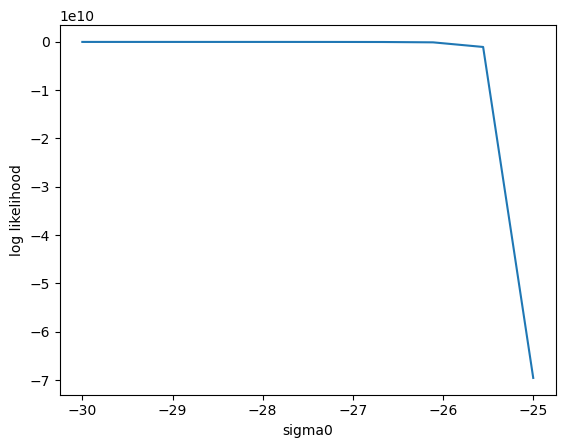

In [65]:
plt.plot(log_s0, log_liks)
plt.xlabel('sigma0')
plt.ylabel('log likelihood')

In [41]:
import cProfile
cProfile.run('log_lik(-27, obs_subset, vars_subset, nfws_subset)')

         9563 function calls (9543 primitive calls) in 0.005 seconds

   Ordered by: standard name

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.003    0.003 3684346576.py:11(<listcomp>)
        1    0.000    0.000    0.005    0.005 3684346576.py:2(log_lik)
       20    0.000    0.000    0.000    0.000 <frozen abc>:117(__instancecheck__)
        1    0.000    0.000    0.000    0.000 <frozen importlib._bootstrap>:405(parent)
        1    0.000    0.000    0.005    0.005 <string>:1(<module>)
      142    0.000    0.000    0.002    0.000 converters.py:133(converters_and_unit)
      142    0.000    0.000    0.000    0.000 converters.py:171(<listcomp>)
      395    0.000    0.000    0.000    0.000 converters.py:176(<genexpr>)
       60    0.000    0.000    0.001    0.000 core.py:1025(_get_converter)
       10    0.000    0.000    0.000    0.000 core.py:1042(<lambda>)
       60    0.000    0.000    0.001    0.000 core.py:1063(_to)
 

In [67]:
ndim = 1
nwalkers = 5
nsteps = 1000
initial = np.random.uniform(low=-50, high=-20, size=(nwalkers, ndim)).astype(np.float128)

In [48]:
sampler = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
start = time.time()
sampler.run_mcmc(initial, nsteps, progress=True)
end = time.time()
serial_time = end - start
print("Serial took {0:.1f} seconds".format(serial_time))

100%|██████████████████████████████████████| 1000/1000 [00:07<00:00, 137.84it/s]

Serial took 7.3 seconds


In [49]:
from multiprocessing import cpu_count

ncpu = cpu_count()
print("{0} CPUs".format(ncpu))

8 CPUs


In [68]:
from multiprocessing import Pool

with Pool() as pool:
    sampler = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
    start = time.time()
    state = sampler.run_mcmc(initial, nsteps, progress=True)
    end = time.time()
    multi_time = end - start
    print("Multiprocessing took {0:.1f} seconds".format(multi_time))
    print("{0:.1f} times faster than serial".format(serial_time / multi_time))
    
    nsteps = 10000
    sampler.run_mcmc(state, nsteps, progress = True)

100%|███████████████████████████████████████| 1000/1000 [01:14<00:00, 13.48it/s]


Multiprocessing took 74.3 seconds
0.1 times faster than serial


100%|█████████████████████████████████████| 10000/10000 [12:12<00:00, 13.65it/s]


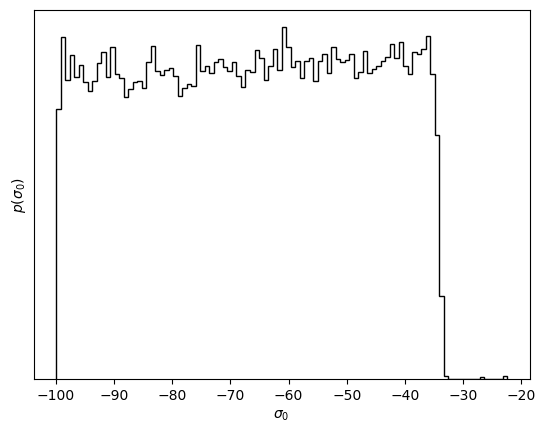

In [69]:
import matplotlib.pyplot as plt

samples = sampler.get_chain(flat=True)
plt.hist(samples[:, 0], 100, color="k", histtype="step")
plt.xlabel(r"$\sigma_0$")
plt.ylabel(r"$p(\sigma_0)$")
plt.gca().set_yticks([]);

In [70]:
print(
    "Mean acceptance fraction: {0:.3f}".format(
        np.mean(sampler.acceptance_fraction)
    )
)

Mean acceptance fraction: 0.831


In [71]:
print(
    "Mean autocorrelation time: {0:.3f} steps".format(
        np.mean(sampler.get_autocorr_time())
    )
)

Mean autocorrelation time: 31.871 steps


In [73]:
np.median(samples)

-66.35362903211761

In [74]:
# with 10*Agn heating rate
with Pool() as pool:
    sampler2 = emcee.EnsembleSampler(nwalkers,
                                ndim,
                                log_lik,
                                args=[obs_subset, vars_subset, nfws_subset])
    start = time.time()
    state = sampler2.run_mcmc(initial, 1000, progress=True)
    end = time.time()
    multi_time = end - start
    print("Multiprocessing took {0:.1f} seconds".format(multi_time))
    print("{0:.1f} times faster than serial".format(serial_time / multi_time))
    
    nsteps = 10000
    sampler2.run_mcmc(state, nsteps, progress = True)

100%|█████████████████████████████████████| 10000/10000 [29:06<00:00,  5.73it/s]


Multiprocessing took 1746.7 seconds
0.0 times faster than serial


100%|█████████████████████████████████████| 10000/10000 [19:55<00:00,  8.36it/s]


(-28.0, -24.0)

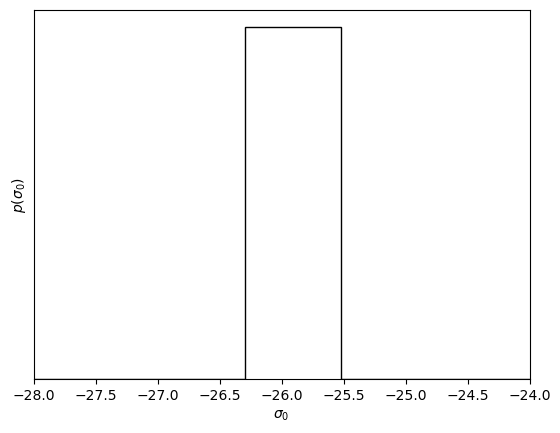

In [81]:
#plot after multiplying agn heating by 10

samples2 = sampler2.get_chain(flat=True)
plt.hist(samples2[:, 0], 100, color="k", histtype="step")
plt.xlabel(r"$\sigma_0$")
plt.ylabel(r"$p(\sigma_0)$")
plt.gca().set_yticks([]);
plt.xlim(-28,-24)

In [78]:
np.median(samples2)

-25.874611711596405